In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [25]:
batch_size = 128

data_transform = transforms.Compose([
    transforms.ToTensor()
])

train_dataset = datasets.FashionMNIST(
    root = "./data",
    train = True,
    download = True,
    transform=  data_transform
)

test_dataset = datasets.MNIST(
    root = "./data",
    train = False,
    download = True,
    transform=  data_transform
)

train_loader = DataLoader( train_dataset, batch_size=batch_size, shuffle=True)


100%|██████████| 26.4M/26.4M [00:03<00:00, 8.65MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 203kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.76MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 3.94MB/s]


In [27]:
latent_size = 128

class VAE(nn.Module):

  def __init__(self, input_dim = 784, hidden_dim = 256, latent_dim = latent_size):
    super().__init__()

    # encoder
    self.fc1 = nn.Linear(input_dim, hidden_dim)
    self.fc_mu = nn.Linear(hidden_dim, latent_dim)
    self.fc_logvar = nn.Linear(hidden_dim, latent_dim)

    # decoder
    self.fc2 = nn.Linear(latent_dim, hidden_dim)
    self.fc3 = nn.Linear(hidden_dim, input_dim)
    self.relu = nn.ReLU()
    self.sigmoid = nn.Sigmoid()

  def encode(self,x):
    h = self.relu(self.fc1(x))
    mu = self.fc_mu(h)
    logvar = self.fc_logvar(h)

    return mu, logvar

  def reparameterize(self, mu,  logvar):
    std = torch.exp(0.5*logvar)
    eps = torch.randn_like(std)

    z = mu + std*eps
    return z

  def decode(self, z):
    o = self.fc2(z)
    o = self.relu(o)
    o = self.fc3(o)
    o = self.sigmoid(o)

    return o

  # forward pass
  def forward(self,x):
      mu, logvar = self.encode(x)
      z = self.reparameterize(mu, logvar)
      x_recon = self.decode(z)

      return x_recon, mu, logvar


In [28]:
# loss

def vae_loss(x, x_recon, mu, logvar):
  reconstruction_loss = nn.functional.binary_cross_entropy(x_recon, x, reduction = "sum")
  kl_divervence = 0.5* torch.sum(mu**2 + torch.exp(logvar) - logvar -1)

  return reconstruction_loss + kl_divervence

In [29]:
model = VAE().to(device)
optimizer = optim.Adam(model.parameters(), lr = 1e-3)

In [30]:
epochs = 10
model.train()

for epoch in range(epochs):
  total_loss = 0
  for x,_ in train_loader:
    x = x.view(-1, 784).to(device)

    optimizer.zero_grad()
    x_recon, mu, logvar = model(x)
    loss = vae_loss(x, x_recon, mu, logvar)

    loss.backward()
    optimizer.step()

    total_loss += loss.item()

  print(f"Epoch: {epoch+1}, Loss: {total_loss/len(train_loader.dataset)}")

Epoch: 1, Loss: 302.63403743489584
Epoch: 2, Loss: 271.22318531901044
Epoch: 3, Loss: 261.40832802734377
Epoch: 4, Loss: 254.89986334635418
Epoch: 5, Loss: 250.9701849283854
Epoch: 6, Loss: 248.6959318684896
Epoch: 7, Loss: 247.21885205078124
Epoch: 8, Loss: 246.18236256510417
Epoch: 9, Loss: 245.38778522135416
Epoch: 10, Loss: 244.73545260416665


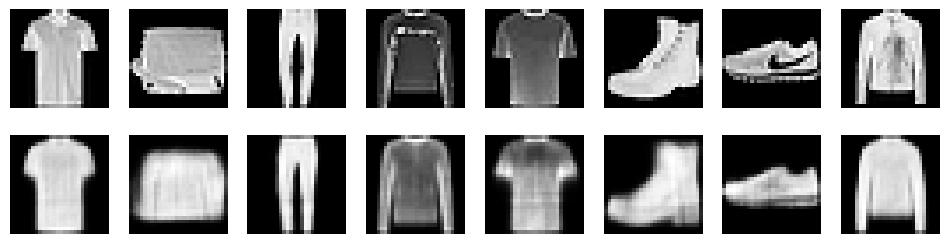

In [31]:
model.eval()

with torch.no_grad():
  x, _ = next(iter(train_loader))
  x = x.view(-1, 784).to(device)

  x_recon_images, mu, logvar = model(x) # Unpack the output correctly

  n = 8

  plt.figure(figsize = (12,3))

  for i in range(n):
    plt.subplot(2, n, i+1)
    plt.imshow(x[i].cpu().view(28,28), cmap = "gray")
    plt.axis("off")

    plt.subplot(2,n, i+n+1)
    plt.imshow(x_recon_images[i].cpu().view(28,28), cmap = "gray") # Use x_recon_images[i] to get individual reconstructed images
    plt.axis("off")

  plt.show()

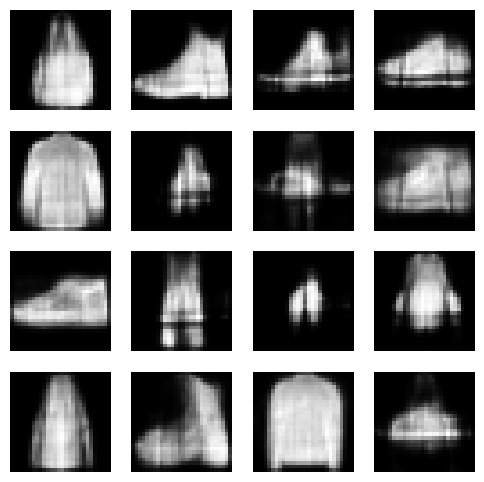

In [32]:
with torch.no_grad():
    z = torch.randn(16, latent_size).to(device)
    samples = model.decode(z).cpu()

plt.figure(figsize=(6, 6))

for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(samples[i].view(28, 28), cmap="gray")
    plt.axis("off")

plt.show()